Reference dataset (best_i=0): TCGA-BRCA


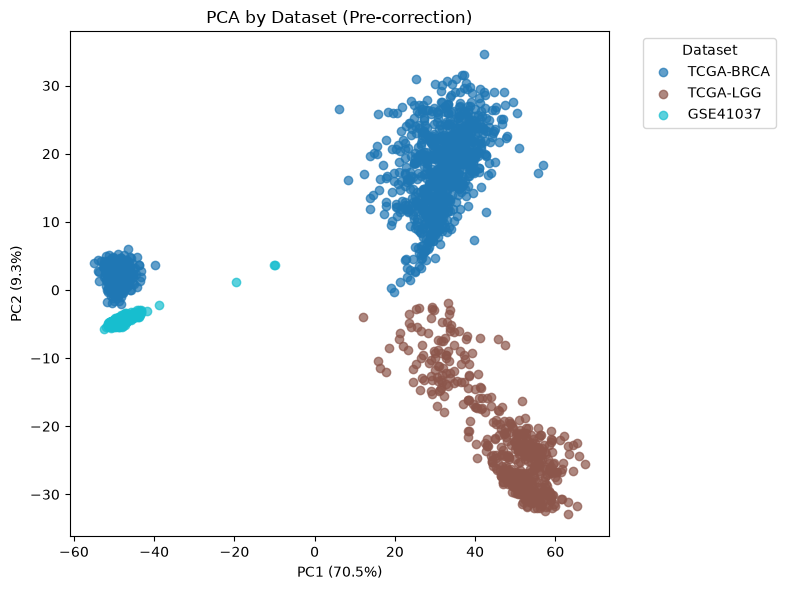

[WARNING] 18 samples with missing covariates in covar_mod. They are removed from the data. You may want to double check your covariates.


TCGA-LGG: 12,023 CpGs valid for correction (24.5% of all CpGs)
GSE41037: 13,297 CpGs valid for correction (27.1% of all CpGs)


[WARNING] 16 samples with missing covariates in covar_mod. They are removed from the data. You may want to double check your covariates.


Saved TCGA-BRCA → /work/gr-fe/bryan/EpiHydra/data/03_final/TCGA-BRCA/methylation.pkl (1097 samples, 49156 CpGs)
Saved TCGA-LGG → /work/gr-fe/bryan/EpiHydra/data/03_final/TCGA-LGG/methylation.pkl (498 samples, 49156 CpGs)
Saved GSE41037 → /work/gr-fe/bryan/EpiHydra/data/03_final/GSE41037/methylation.pkl (704 samples, 49156 CpGs)

Building combined dataset from: ['TCGA-BRCA', 'TCGA-LGG', 'GSE41037']
Final combined matrix shape: (49156, 2299)
Missing values: 54,139,505 (47.9%)


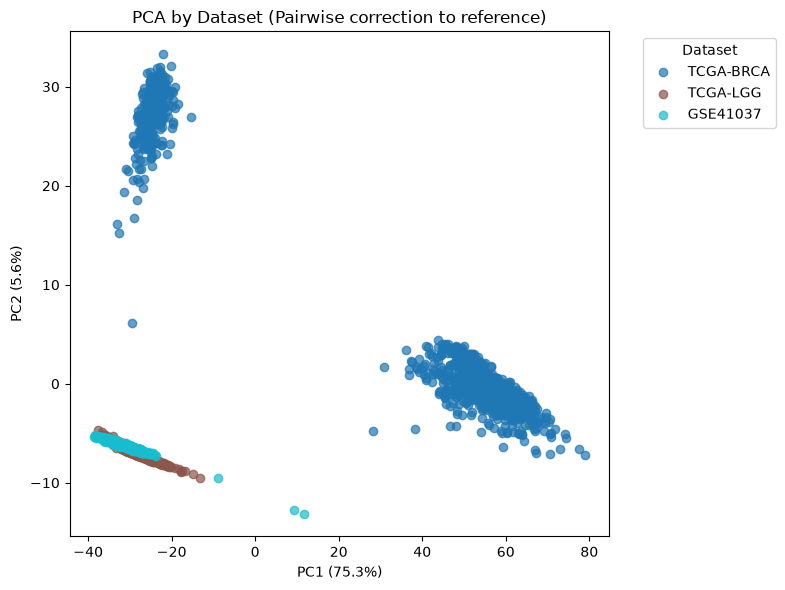


Combined dataset saved successfully.


In [6]:
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from sklearn.decomposition import PCA
from inmoose.pycombat import pycombat_norm
import os

# ── Configuration ─────────────────────────────────────────────────────────────
ALL_DATASETS = ['TCGA-BRCA' , 'TCGA-LGG' , 'GSE41037']

# Select which datasets to include in the combined output
# Change this list to select a subset e.g. ['GSE27097', 'GSE40279']
DATASETS_TO_COMBINE = ['TCGA-BRCA' , 'TCGA-LGG' , 'GSE41037']
#DATASETS_TO_COMBINE = ALL_DATASETS

# Set to True to save each dataset individually to 03_final
SAVE_INDIVIDUAL = True

# ── Load data ─────────────────────────────────────────────────────────────────
cpgs = pd.read_csv('/work/gr-fe/bryan/EpiHydra/data/03_final/methylgpt/probe_ids_type3.csv')['illumina_probe_id']

cpg_list = []
meta_list = []
max_i = 0
best_i = 0

for i, data in enumerate(ALL_DATASETS):
    filepath = f'/work/gr-fe/bryan/EpiHydra/data/02_processed/{data}/methylation.pkl'

    with open(filepath, 'rb') as file:
        methylation = pickle.load(file)

    cpg_list.append(methylation['CpG'].reindex(cpgs))
    methylation['meta']['Dataset'] = [data for _ in range(methylation['meta'].shape[0])]
    meta_list.append(methylation['meta'])
    del methylation

    if cpg_list[i].shape[1] > max_i:
        max_i = cpg_list[i].shape[1]
        best_i = i

print(f"Reference dataset (best_i={best_i}): {ALL_DATASETS[best_i]}")

# ── Helper plot function ──────────────────────────────────────────────────────
def plot_pca(X, meta_df, title):
    X_filled = X.fillna(X.median()).dropna()
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X_filled.T)

    datasets = meta_df['Dataset'].unique()
    colours = cm.tab10(np.linspace(0, 1, len(datasets)))
    colour_map = dict(zip(datasets, colours))

    fig, ax = plt.subplots(figsize=(8, 6))

    for dataset in datasets:
        mask = meta_df['Dataset'] == dataset
        ax.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            label=dataset,
            color=colour_map[dataset],
            alpha=0.7
        )

    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
    ax.set_title(title)
    ax.legend(title='Dataset', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

# ── Pre-correction PCA ────────────────────────────────────────────────────────
combined_pre = pd.concat(cpg_list, axis=1)
combined_meta_pre = pd.concat(meta_list)
plot_pca(combined_pre, combined_meta_pre, 'PCA by Dataset (Pre-correction)')
del combined_pre, combined_meta_pre

# ── Pairwise batch correction to reference ────────────────────────────────────
ref_cpg  = cpg_list[best_i].copy()
ref_meta = meta_list[best_i].copy()
ref_meta['Dataset'] = ALL_DATASETS[best_i]

# Store all corrected datasets keyed by name for easy access later
corrected_store = {ALL_DATASETS[best_i]: {'CpG': ref_cpg, 'meta': ref_meta}}

for i, (cpg_df, meta_df) in enumerate(zip(cpg_list, meta_list)):
    if i == best_i:
        continue

    # ── Find CpGs with no NaN in EITHER dataset — required for pycombat ───────
    valid_cpgs_ref = ref_cpg.index[~ref_cpg.isna().any(axis=1)]
    valid_cpgs_ds  = cpg_df.index[~cpg_df.isna().any(axis=1)]
    valid_cpgs = list(set(valid_cpgs_ref) & set(valid_cpgs_ds))

    print(f"{ALL_DATASETS[i]}: {len(valid_cpgs):,} CpGs valid for correction "
          f"({len(valid_cpgs)/len(ref_cpg.index)*100:.1f}% of all CpGs)")

    # ── Subset both datasets to NaN-free CpGs ─────────────────────────────────
    ref_subset = ref_cpg.loc[valid_cpgs]
    ds_subset  = cpg_df.loc[valid_cpgs]

    # ── Combine and build batch vector ────────────────────────────────────────
    combined = pd.concat([ref_subset, ds_subset], axis=1)
    batch = [0] * ref_subset.shape[1] + [1] * ds_subset.shape[1]

    # ── Age covariate ─────────────────────────────────────────────────────────
    covar_age = pd.DataFrame(
        {'age': np.concatenate([ref_meta['age'].values, meta_df['age'].values])},
        index=combined.columns
    )

    # ── Correct — ref_batch=0 keeps reference samples unchanged ───────────────
    corrected = pycombat_norm(
        combined,
        batch,
        ref_batch=0,
        covar_mod=covar_age,
        na_cov_action='remove'
    )

    # ── Extract corrected target samples only ─────────────────────────────────
    corrected_ds = corrected.iloc[:, ref_subset.shape[1]:]

    # ── Place corrected values into full reference CpG space ──────────────────
    corrected_full = pd.DataFrame(
        np.nan,
        index=ref_cpg.index,
        columns=corrected_ds.columns
    )
    corrected_full.loc[valid_cpgs] = corrected_ds.values

    meta_df = meta_df[meta_df['ID'].isin(corrected_full.columns)]
    corrected_store[ALL_DATASETS[i]] = {'CpG': corrected_full, 'meta': meta_df}

# ── Save individual datasets to 03_final ─────────────────────────────────────
if SAVE_INDIVIDUAL:
    for dataset_name, data in corrected_store.items():
        out_dir = f'/work/gr-fe/bryan/EpiHydra/data/03_final/{dataset_name}'
        os.makedirs(out_dir, exist_ok=True)
        out_path = f'{out_dir}/methylation.pkl'

        with open(out_path, 'wb') as file:
            pickle.dump(data, file)

        print(f"Saved {dataset_name} → {out_path} "
              f"({data['CpG'].shape[1]} samples, {data['CpG'].shape[0]} CpGs)")

# ── Build combined from selected subset ───────────────────────────────────────
print(f"\nBuilding combined dataset from: {DATASETS_TO_COMBINE}")

missing = [d for d in DATASETS_TO_COMBINE if d not in corrected_store]
if missing:
    raise ValueError(f"These datasets were not corrected and cannot be combined: {missing}")

combined_cpg  = pd.concat([corrected_store[d]['CpG']  for d in DATASETS_TO_COMBINE], axis=1)
combined_meta = pd.concat([corrected_store[d]['meta'] for d in DATASETS_TO_COMBINE])

print(f"Final combined matrix shape: {combined_cpg.shape}")
print(f"Missing values: {combined_cpg.isna().sum().sum():,} "
      f"({combined_cpg.isna().mean().mean()*100:.1f}%)")

# ── Post-correction PCA ───────────────────────────────────────────────────────
plot_pca(combined_cpg, combined_meta, 'PCA by Dataset (Pairwise correction to reference)')

# ── Save combined ─────────────────────────────────────────────────────────────
combined_df = {
    'CpG': combined_cpg,
    'meta': combined_meta
}

os.makedirs('/work/gr-fe/bryan/EpiHydra/data/03_final/combined', exist_ok=True)

with open('/work/gr-fe/bryan/EpiHydra/data/03_final/combined/methylation.pkl', 'wb') as file:
    pickle.dump(combined_df, file)

print("\nCombined dataset saved successfully.")
